In [1]:
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
df = pd.read_csv("/content/smartcart_dataset (1).csv")
FEATURES = ["price", "weight_kg","rating", "discount_pct", "description_length"]

TARGET = "category"
df.head()

,price,weight_kg,rating,discount_pct,description_length,category
0,438.29,3.413,4.1,57.5,47,Apparel
1,719.57,6.111,3.5,46.5,45,Apparel
2,1202.48,9.337,4.1,23.7,109,Electronics
3,316.98,2.752,4.4,21.9,20,Grocery
4,2037.38,6.407,3.6,14.1,93,Electronics


In [5]:
X = df[FEATURES].values
y_raw = df[TARGET].values

label_encoder = LabelEncoder()            # Encode target labels
y = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert training data into tensors
X_train_tf = tf.convert_to_tensor(X_train_scaled, dtype=tf.float32)
y_train_tf = tf.convert_to_tensor(y_train, dtype=tf.int32)

# Convert testing data into tensors
X_test_tf = tf.convert_to_tensor(X_test_scaled, dtype=tf.float32)
y_test_tf = tf.convert_to_tensor(y_test, dtype=tf.int32)

print("Data splitting and scaling completed successfully!")
print("X_train:", X_train_tf.shape)
print("X_test:", X_test_tf.shape)

Data splitting and scaling completed successfully!
X_train: (960, 5)
X_test: (240, 5)


In [9]:
model = Sequential()

model.add(Dense(32, activation="relu", input_dim=X_train_scaled.shape[1]))
model.add(Dense(16, activation="relu"))
model.add(Dense(3, activation="softmax"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
def forward(model, X):
    return model(X, training=True)

In [11]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()
def compute_loss(y_true, y_pred):
    return loss_fn(y_true, y_pred)

In [12]:
def backward(model, X, y_true):
    with tf.GradientTape() as tape:
        y_pred = forward(model, X)
        loss = compute_loss(y_true, y_pred)

    gradients = tape.gradient(loss, model.trainable_variables)
    return loss, gradients

In [13]:
optimizer = keras.optimizers.SGD(learning_rate=0.1)

def update(model, gradients, optimizer):
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

Epoch    0 │ Loss: 1.0604
Epoch   50 │ Loss: 0.2829
Epoch  100 │ Loss: 0.2166
Epoch  150 │ Loss: 0.1904
Epoch  200 │ Loss: 0.1765
Epoch  250 │ Loss: 0.1678
Epoch  300 │ Loss: 0.1617
Epoch  350 │ Loss: 0.1575
Epoch  400 │ Loss: 0.1545
Epoch  450 │ Loss: 0.1520


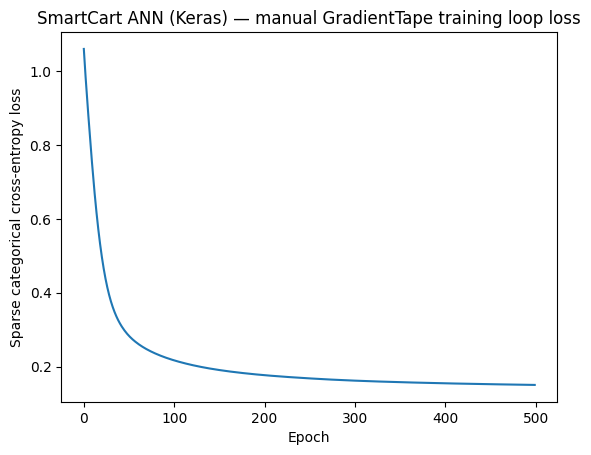

In [14]:
loss_history = []
for epoch in range(500):
    loss, gradients = backward(model, X_train_tf, y_train_tf)
    update(model, gradients, optimizer)

    loss_history.append(float(loss))

    if epoch % 50 == 0:
        print(f"Epoch {epoch:4d} │ Loss: {float(loss):.4f}")
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy loss")
plt.title("SmartCart ANN (Keras) — manual GradientTape training loop loss")
plt.show()

In [15]:
test_probs = model(X_test_tf, training=False)       # no training here

y_pred = np.argmax(test_probs.numpy(), axis=1)      # highest-probability class

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

Test accuracy: 0.9417
